# 05 Rooftop solar

Does rooftop solar break the detectors from notebooks 03 and 04?

| Run | Feeder | Season | Customers | Rooftop PV |
|---|---|---|---|---|
| winter (notebooks 01-04) | SimBench `1-LV-semiurb4--0-sw` | 1-28 January | 41 | 1 unit, 6 kWp |
| summer_pv (this notebook) | SimBench `1-LV-semiurb4--2-sw` (the 2034 scenario of the same feeder) | 1-28 June | 58 | 6 units, 172 kWp |

Everything else is unchanged: the same meters, scenarios, detectors and classifier, run again on the summer feeder (`grid.use_run`). Two choices to note:

- SimBench gives all 6 PV units the same profile, so each unit gets a small variation of its own (10 %, for roof direction and shading), like the 30 % already used for customer demand.
- The feeder's 4 home batteries are switched off. They would smooth exactly the signals under test, and how they are controlled is a separate question.

Step 1 runs the existing five classes on the solar feeder. Step 2 adds a noise-aware energy balance and three solar-specific cases: a passing cloud, an inverter trip, and an attack that starts during a cloud.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("pandapower").setLevel(logging.ERROR)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
import grid, pipeline, evaluate as ev, scenarios as sc

## The solar feeder

Transformer power over the same week of each run. Below zero, the feeder exports to the MV grid.

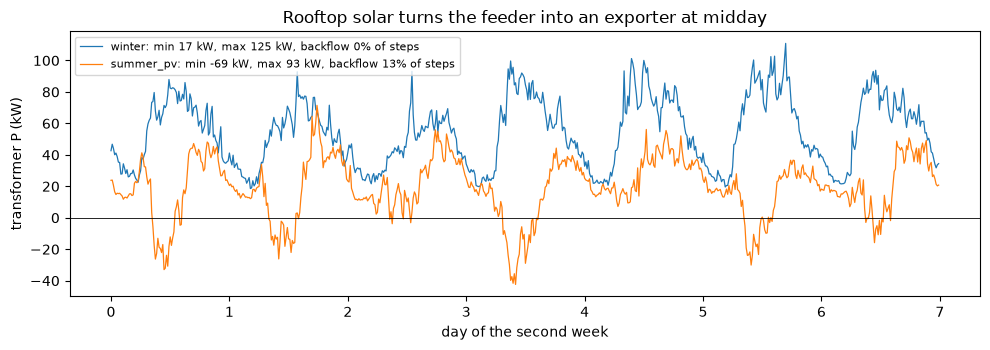

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for name, colour in [("winter", "tab:blue"), ("summer_pv", "tab:orange")]:
    grid.use_run(name)
    p = -grid.load_results()["res_trafo.p_lv_mw"].iloc[:, 0] * 1e3
    week = p.iloc[7 * 96: 14 * 96].reset_index(drop=True)
    ax.plot(np.arange(len(week)) / 96, week, color=colour, lw=0.9, label=f"{name}: min {p.min():.0f} kW, max {p.max():.0f} kW, backflow {(p < 0).mean():.0%} of steps")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("day of the second week"); ax.set_ylabel("transformer P (kW)")
ax.set_title("Rooftop solar turns the feeder into an exporter at midday"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "pv_backflow.png", dpi=150)

## Run both

The winter run reuses its saved data. The summer run is rebuilt if missing (about 8 minutes the first time).

In [3]:
runs = {name: pipeline.run(name) for name in ["winter", "summer_pv"]}
comparison = pd.DataFrame({name: pipeline.summary(*r) for name, r in runs.items()})
comparison

,winter,summer_pv
WLS: mean J on normal episodes (dof 5),4.960,4.952
WLS: chi-square alarm rate on normal,0.049,0.045
Energy balance: residual std (kW),0.489,0.523
Peer + balance: load_change events detected,0.683,0.300
Peer + balance: meter_fault events detected,0.167,0.067
Peer + balance: attack events detected,0.383,0.217
Peer + balance: consistent attacks detected,0.500,0.167
Peer + balance: false alarms,0.006,0.007
Classifier: load_change events detected,0.929,0.286
Classifier: meter_fault events detected,0.667,0.667


Rows marked *Classifier* are on the test weeks only (days 22-28 of each run); the rest are on all 300 episodes.

## Consistent attacks: the size needed to be seen

winter               summer_pv              
             steps  chi2 balance     steps  chi2 balance
size                                                    
[0.0, 0.25)    433  0.05    0.06       960  0.06    0.01
[0.25, 0.5)    249  0.08    0.23       156  0.12    0.12
[0.5, 1.0)     251  0.29    0.67       118  0.21    0.41
[1.0, 2.0)     221  0.66    0.87        38  0.74    0.53
[2.0, 4.0)     149  0.98    0.96        25  1.00    0.92
[4.0, inf)      77  1.00    1.00        83  1.00    1.00

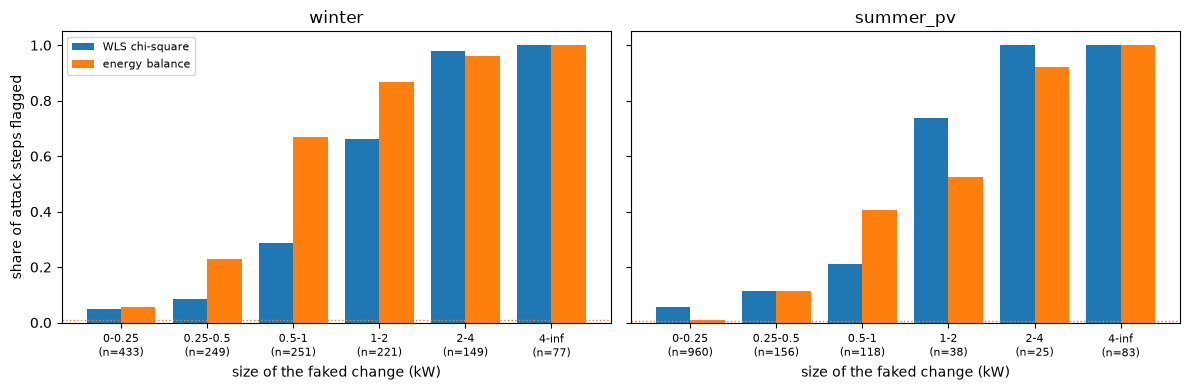

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
tables = {}
for ax, (name, (data, out)) in zip(axs, runs.items()):
    tab = ev.attack_size_table(data, out); ref = ev.reference_rates(data, out); tables[name] = tab
    x = np.arange(len(tab))
    ax.bar(x - 0.2, tab.chi2, 0.4, label="WLS chi-square", color="tab:blue")
    ax.bar(x + 0.2, tab.balance, 0.4, label="energy balance", color="tab:orange")
    ax.axhline(ref.balance, color="tab:orange", ls=":", lw=1)
    ax.set_xticks(x, [f"{iv.left:g}-{iv.right:g}\n(n={n})" for iv, n in zip(tab.index, tab.steps)], fontsize=8)
    ax.set_title(name); ax.set_xlabel("size of the faked change (kW)")
axs[0].set_ylabel("share of attack steps flagged"); axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "attack_size_pv.png", dpi=150)
pd.concat(tables, axis=1).round(2)

## Peer check: solar customers vs the rest

Residual std of each meter's peer model on normal history (median over meters). Lower means the peers predict it better, so smaller deviations can be seen.

In [5]:
pd.concat({name: pipeline.peer_quality(*r) for name, r in runs.items()}, axis=0).round(3)

residual std (kW)  residual / mean |P|
          PV customer                                        
winter    False                    0.245                0.699
          True                     0.316                0.214
summer_pv False                    0.181                0.579
          True                     0.330                0.260

## Step 2a: a noise-aware energy balance

The plain balance check divides the mismatch by one fixed std for the whole day. But meter error is proportional to the reading, so with rooftop PV the meters are noisiest at midday. The noise-aware version divides each step's mismatch by the std expected from the meters' own accuracy at that step (`detectors.fit_balance_noise_aware`). It is kept as a separate variant (`balance_nw`), so the published winter results do not change.

In [6]:
nw_tables = {}
for name, (data, out) in runs.items():
    fl = {"chi2": out["wls"].flag, "balance": out["bal_flag"], "balance_nw": out["bal_nw_flag"]}
    nw_tables[name] = ev.attack_size_table(data, out, flags=fl).drop(columns="steps")
    nw_tables[name].loc["alarm rate on real load changes"] = ev.reference_rates(data, out, fl)
pd.concat(nw_tables, axis=1).round(2)

winter                    summer_pv          \
                                  chi2 balance balance_nw      chi2 balance   
size                                                                          
[0.0, 0.25)                       0.05    0.06       0.06      0.06    0.01   
[0.25, 0.5)                       0.08    0.23       0.27      0.12    0.12   
[0.5, 1.0)                        0.29    0.67       0.69      0.21    0.41   
[1.0, 2.0)                        0.66    0.87       0.88      0.74    0.53   
[2.0, 4.0)                        0.98    0.96       0.96      1.00    0.92   
[4.0, inf)                        1.00    1.00       1.00      1.00    1.00   
alarm rate on real load changes   0.05    0.01       0.00      0.05    0.01   

                                            
                                balance_nw  
size                                        
[0.0, 0.25)                           0.04  
[0.25, 0.5)                           0.33  
[0.5, 1.0)                            0.58  
[1.0, 2.0)                            0.71  
[2.0, 4.0)                            0.96  
[4.0, inf)                            1.00  
alarm rate on real load changes       0.00

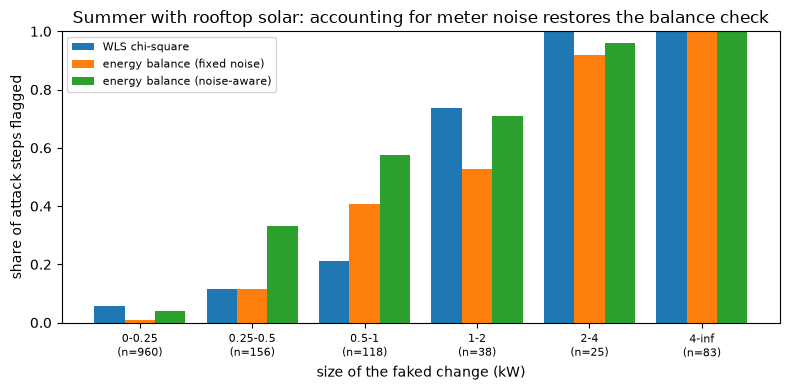

In [7]:
data, out = runs["summer_pv"]
fl = {"chi2": out["wls"].flag, "balance": out["bal_flag"], "balance_nw": out["bal_nw_flag"]}
tab = ev.attack_size_table(data, out, flags=fl)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(tab)); w = 0.27
for i, (k, c, lab) in enumerate([("chi2", "tab:blue", "WLS chi-square"), ("balance", "tab:orange", "energy balance (fixed noise)"),
                                 ("balance_nw", "tab:green", "energy balance (noise-aware)")]):
    ax.bar(x + (i - 1) * w, tab[k], w, color=c, label=lab)
ax.set_xticks(x, [f"{iv.left:g}-{iv.right:g}\n(n={n})" for iv, n in zip(tab.index, tab.steps)], fontsize=8)
ax.set_xlabel("size of the faked change (kW)"); ax.set_ylabel("share of attack steps flagged"); ax.set_ylim(0, 1)
ax.set_title("Summer with rooftop solar: accounting for meter noise restores the balance check")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / "attack_size_noise_aware.png", dpi=150)

In [8]:
pd.DataFrame({name: {"plain balance": ev.detection(d["episodes"][~d["episodes"].subtype.isin(sc.PV_SUBTYPES)], o["pred"]["balance"]).groupby("cls").detected.mean().get("attack"),
                     "noise-aware balance": ev.detection(d["episodes"][~d["episodes"].subtype.isin(sc.PV_SUBTYPES)], o["pred_extra"]["balance_nw"]).groupby("cls").detected.mean().get("attack")}
              for name, (d, o) in runs.items()}).round(2).rename_axis("attack events detected (rule 3)")

,winter,summer_pv
attack events detected (rule 3),,
plain balance,0.38,0.22
noise-aware balance,0.38,0.22


The feeder-level alarm gets much more sensitive, but per-event detection by rule 3 does not change. Rule 3 only asks the balance *after* the peer check has flagged a meter, so in summer the peer check is now the bottleneck.

## Step 2b: solar-specific cases

60 extra episodes on the summer feeder, all starting between 09:00 and 15:00 (`scenarios.plan_pv_episodes`):

| Case | Label | What happens |
|---|---|---|
| Passing cloud (20) | normal | PV on one cable drops to 20-50 % for 30 min-2 h; power flow re-run. Harmless: nothing should be flagged. |
| Inverter trip (20) | load change | One PV inverter goes to zero for the rest of the day. The readings are true, so for the operator this is a real change. |
| Attack in a cloud (20) | attack | A consistent attack that starts at the same moment as a cloud on the target's cable. |

Rules are scored on all 20 episodes of each case; the classifier only on the 5 test-week episodes of each (it saw the other 15 in training).

In [9]:
data, out = runs["summer_pv"]
E = data["episodes"]; pv = E[E.subtype.isin(sc.PV_SUBTYPES)]
preds = {**out["pred"], **out["pred_extra"]}
names = {**ev.NAMES, "ml": "4. Classifier (test weeks)", "balance_nw": "3b. Peer + noise-aware balance"}
rows = {}
for k, p in preds.items():
    sel = pv[pv.split == "test"] if k == "ml" else pv
    d = ev.detection(sel, p)
    clouds = sel[sel.subtype == "cloud"]
    cloud_fa = np.mean([(p.loc[ep].loc[e.event_start: e.event_start + e.cloud_steps + 8].drop(columns="TRAFO") != "normal").to_numpy().mean()
                        for ep, e in clouds.iterrows()])
    rows[names[k]] = {"inverter trip called a load change": d[d.subtype == "pv_trip"].detected.mean(),
                      "attack in a cloud detected": d[d.subtype == "cloud_attack"].detected.mean(),
                      "meter-steps flagged during/after a cloud": cloud_fa}
pv_tab = pd.DataFrame(rows).T
pv_tab["normal-day false alarms"] = [ev.false_alarm_rate(data["labels"].loc[E.index[E.subtype == "none"]], p.loc[E.index[E.subtype == "none"]]) for p in preds.values()]
pv_tab.round(3)

,inverter trip called a load change,attack in a cloud detected,meter-steps flagged during/after a cloud,normal-day false alarms
1. WLS + chi-square + LNR,0.0,0.00,0.000,0.000
2. Peer check,0.0,0.00,0.015,0.006
3. Peer check + energy balance,0.8,0.35,0.015,0.006
4. Classifier (test weeks),0.6,0.80,0.010,0.005
3b. Peer + noise-aware balance,0.8,0.35,0.015,0.006


In [10]:
te = E[(E.split == "test") & (E.subtype == "none")]
print("classifier chance level on test normal days:", ev.chance_detection(te, out["pred"]["ml"]).round(2).to_dict())
fl = {"chi2": out["wls"].flag, "balance": out["bal_flag"], "balance_nw": out["bal_nw_flag"]}
ev.attack_size_table(data, out, flags=fl, subtypes=("cloud_attack",)).round(2)

classifier chance level on test normal days: {'load_change': 0.07, 'meter_fault': 0.0, 'comm_loss': 0.0, 'attack': 0.0}


,steps,chi2,balance,balance_nw
size,,,,
"[0.0, 0.25)",510,0.04,0.02,0.05
"[0.25, 0.5)",118,0.12,0.06,0.15
"[0.5, 1.0)",79,0.18,0.51,0.58
"[1.0, 2.0)",91,0.76,0.82,0.82
"[2.0, 4.0)",35,1.00,0.97,1.00
"[4.0, inf)",118,1.00,0.99,1.00


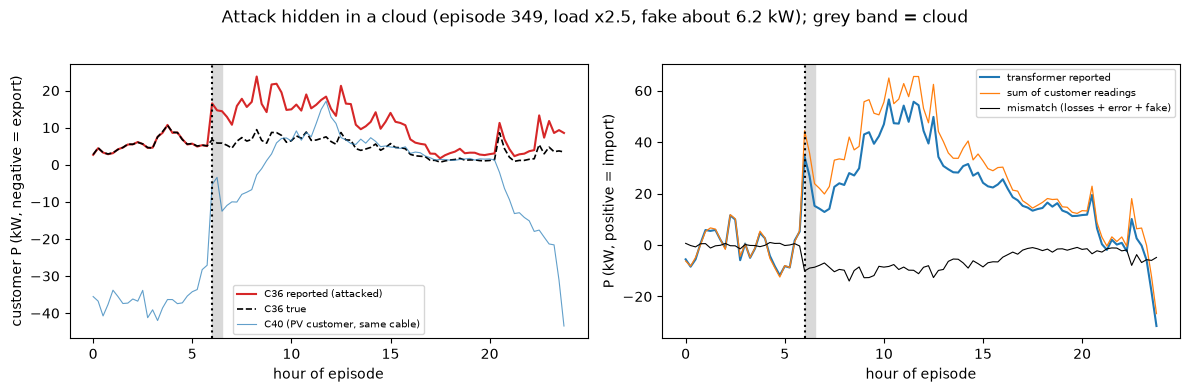

In [11]:
D = data["defs"]
pid = lambda m: D.index[(D.meter == m) & (D.meas_type == "p")][0]
# the cloud attack with the largest faked change, so the fake is visible
fake_kw = {ep: (data["readings"].loc[ep][pid(e.target_meter)] - data["true"].loc[ep][pid(e.target_meter)]).loc[e.event_start:].abs().mean() * 1e3
           for ep, e in pv[(pv.subtype == "cloud_attack") & (pv.split == "train")].iterrows()}
ep = max(fake_kw, key=fake_kw.get); e = E.loc[ep]
R, T = data["readings"].loc[ep], data["true"].loc[ep]
tp = D.index[(D.meter == "TRAFO") & (D.meas_type == "p")][0]
pv_meters = [f"C{b}" for b in grid.load_net().sgen.bus[grid.load_net().sgen.gateway == e.gateway]]
hours = np.arange(96) / 4
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(hours, R[pid(e.target_meter)] * 1e3, color="tab:red", label=f"{e.target_meter} reported (attacked)")
axs[0].plot(hours, T[pid(e.target_meter)] * 1e3, "--", color="k", lw=1.2, label=f"{e.target_meter} true")
for m in pv_meters:
    axs[0].plot(hours, R[pid(m)] * 1e3, lw=0.8, alpha=0.7, label=f"{m} (PV customer, same cable)")
axs[0].set_ylabel("customer P (kW, negative = export)"); axs[0].legend(fontsize=7)
axs[1].plot(hours, -R[tp] * 1e3, color="tab:blue", label="transformer reported")
customers = [m for m in data["labels"].columns if m != "TRAFO"]
axs[1].plot(hours, R[[pid(m) for m in customers]].sum(axis=1) * 1e3, color="tab:orange", lw=0.9,
            label="sum of customer readings")
axs[1].plot(hours, -R[tp] * 1e3 - R[[pid(m) for m in customers]].sum(axis=1) * 1e3, color="k", lw=0.8,
            label="mismatch (losses + error + fake)")
axs[1].set_ylabel("P (kW, positive = import)"); axs[1].legend(fontsize=7)
for ax in axs:
    ax.axvspan(e.event_start / 4, (e.event_start + e.cloud_steps) / 4, color="0.85", label="cloud")
    ax.axvline(e.event_start / 4, color="k", ls=":"); ax.set_xlabel("hour of episode")
fig.suptitle(f"Attack hidden in a cloud (episode {ep}, load x{e.factor:.1f}, fake about {fake_kw[ep]:.1f} kW); grey band = cloud", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "cloud_attack_example.png", dpi=150, bbox_inches="tight")

## Findings

**Step 1: the standard classes on the solar feeder**

- **WLS is unaffected.** On normal days the chi-square test behaves exactly as in winter (mean J about 4.95 for 5 degrees of freedom, about 4.5 % alarms), even with power flowing backwards for 13 % of the time.
- **Detection drops in summer, for two different reasons.**
  1. *Smaller events, not solar.* Summer demand is lower, so the same relative change (a load scaled by 0.2-3x) is smaller in kW: 70 % of consistent-attack steps are below 0.25 kW in summer, against 31 % in winter. Compare by size, not as one number.
  2. *A real solar effect, on the energy balance only.* At the same attack size the plain balance catches fewer attacks in summer (1-2 kW: 53 % vs 87 %), while the chi-square test does not get worse. Meter noise is proportional to the reading, so large PV outputs make the meters noisier at midday: the summer balance mismatch varies twice as much at midday as at night (0.73 vs 0.34 kW), as the meter accuracy predicts (0.65 vs 0.32 kW). WLS weights every reading by its own accuracy; the plain balance check uses one fixed noise level.
- **Peer check.** Solar customers are predicted well *relative to their size* (error about a quarter of their mean power, against more than half for other customers), because neighbours share the same sun. In absolute terms their error is larger, so a fixed-size fault is harder to see at a solar customer.

**Step 2: noise-aware balance and solar cases**

- **Accounting for meter noise restores most of the balance check's sensitivity** in summer (1-2 kW fakes: 53 % to 71 %; 0.5-1 kW: 41 % to 58 %) without more false alarms, and changes almost nothing in winter, where noise varies little. But per-event detection by rule 3 does not improve, because the peer check, which decides *which* meter to look at, is now the weak link.
- **Clouds are harmless to the feeder-level tests**: a real cloud is physically consistent, so the transformer balance holds. They do raise the per-meter false alarms of the peer-based rules during the event, from 0.6 % to about 1.5 % of meter-steps.
- **An inverter trip is recognised as a real change** by rule 3 in most episodes, because the transformer confirms it. The textbook check and the plain peer check cannot say that, as before.
- **Hiding an attack in a cloud does not help the attacker against the balance.** The cloud is real on both sides of the balance, so the fake still shows up as a mismatch of its own size, much like a plain consistent attack. The classifier, trained on such cases, finds most of them in the test weeks, but with 5 test episodes per case that number is rough.

**Limits.** One feeder and one month. Clouds are simple step drops on whole cables, not moving cloud shadows. The home batteries are switched off. Only 20 episodes per solar case, 5 of them in the test weeks.